# Noisy sampling: stock Pauli frames vs. `NoisyCircuitSampler`

Both samplers draw Z-basis outcomes of a Clifford circuit with Pauli (Weyl) noise channels, from the **same distribution**. They differ in how they get there.

| | `Tableau.sample_measurements_noisy_pf` (stock) | `NoisyCircuitSampler` (new) |
|---|---|---|
| per shot | pushes an error frame through **every gate** and draws noise at every channel | draws which noise locations fire, then **adds a precomputed shift** |
| circuit work | proportional to gates × shots, on every call | once per circuit (`compile`), independent of shots and of the noise strength |
| noise rescan | rebuild the circuit and sample again | `sample(..., probs=...)`, no recompilation |

Why it works: an error `W(a, b)` injected at a noise location reaches the measurements as a fixed shift of the outcome (Clifford gates map Paulis to Paulis). The new sampler propagates every (location, Weyl type) pair through the remaining gates once, stores the shifts in an effect table, and applies noise by one matrix product per Weyl type.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from quickqudits import NoisyCircuitSampler, Tableau
from quickqudits.utils.random_circuits import random_circuit

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

GATES = {"H": 1.0, "S": 1.0, "CNOT": 1.5, "CZ": 1.5, "X": 0.5, "Z": 0.5}


def depolarizing(p):
    # Weyl vector p[a*d + b] for d = 2, arranged [[I, Z], [X, Y]]
    return np.array([[1 - p, p / 3], [p / 3, p / 3]])


def noisy_random_circuit(n, size, p, seed):
    qc = random_circuit(n, 2, max_size=size, max_depth=size, gateset=GATES, seed=seed)
    qc.add_noise_global(depolarizing(p))      # one channel after every gate
    return qc


def timed(f):
    t = time.perf_counter()
    out = f()
    return out, time.perf_counter() - t

## 1. A random noisy circuit

In [2]:
n, SIZE, P = 10, 60, 0.02
qc = noisy_random_circuit(n, SIZE, P, seed=7)
sampler, t_compile = timed(lambda: NoisyCircuitSampler(qc))

n_gates = sum(1 for g, _, _ in qc._ops if g.name != "NOISE_CHANNEL")
print(f"{n} qubits, {n_gates} gates, {sampler.n_locations} noise channels (depolarizing p = {P})")
print(f"effect table: {sampler.effects.shape}  (location, Weyl type, measured qubit)")
print(f"compile time: {t_compile * 1e3:.1f} ms")

10 qubits, 60 gates, 88 noise channels (depolarizing p = 0.02)
effect table: (88, 4, 10)  (location, Weyl type, measured qubit)
compile time: 3.2 ms


## 2. The samples

First rows of each sampler (one row = one shot, one column = one qubit), then summary statistics over 100 000 shots.

In [3]:
SHOTS = 100_000
stock, t_stock = timed(lambda: Tableau(n, 2).sample_measurements_noisy_pf(qc, SHOTS, seed=1))
new, t_new = timed(lambda: sampler.sample(SHOTS, seed=2))

print("stock sampler, first 6 shots\n", stock[:6])
print("new sampler,   first 6 shots\n", new[:6])
print(f"\n{SHOTS:,} shots: stock {t_stock:.2f} s, new {t_new:.2f} s  ->  {t_stock / t_new:.1f}x")

stock sampler, first 6 shots
 [[0 1 1 0 1 1 0 1 0 0]
 [1 1 1 1 1 1 1 1 0 1]
 [0 1 0 0 1 0 1 1 1 0]
 [1 1 0 0 1 1 0 0 0 1]
 [1 1 0 1 0 0 0 1 0 1]
 [1 1 0 1 0 1 1 1 1 0]]
new sampler,   first 6 shots
 [[0 1 0 0 1 1 0 0 1 1]
 [0 1 0 1 0 1 1 1 1 1]
 [1 1 1 0 1 0 0 1 1 1]
 [0 1 0 1 1 1 0 1 1 1]
 [0 0 1 1 1 1 1 0 1 1]
 [0 1 1 0 1 0 1 1 1 0]]

100,000 shots: stock 1.41 s, new 0.58 s  ->  2.4x


max |z| over qubits: 1.49 (about 3 or less is expected for statistically equal samplers)


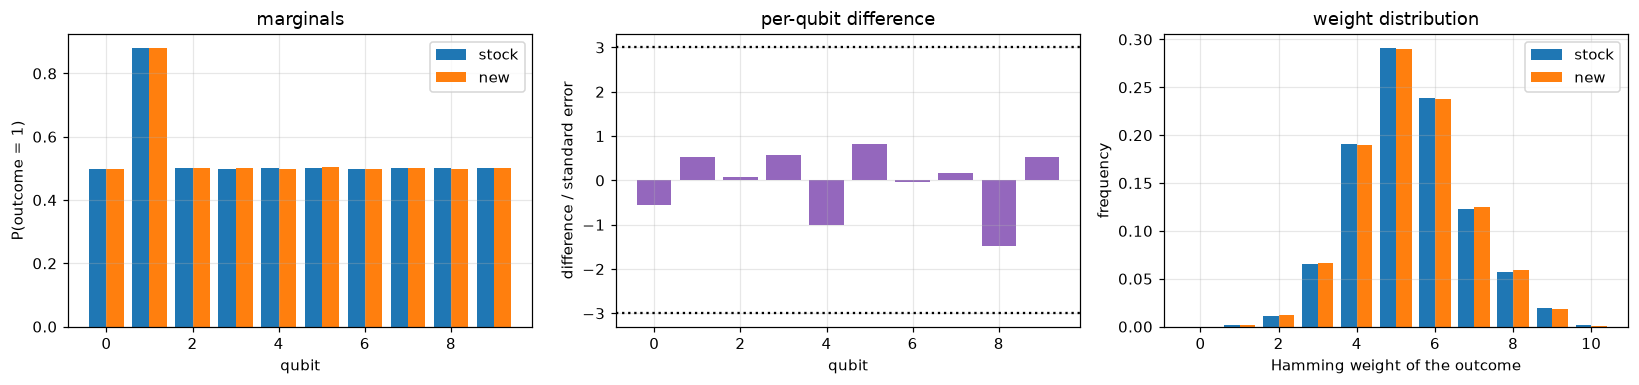

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

m_stock, m_new = stock.mean(0), new.mean(0)
x = np.arange(n)
ax[0].bar(x - 0.2, m_stock, 0.4, label="stock")
ax[0].bar(x + 0.2, m_new, 0.4, label="new")
ax[0].set(xlabel="qubit", ylabel="P(outcome = 1)", title="marginals")
ax[0].legend()

z = (m_new - m_stock) / np.sqrt(2 * m_stock.clip(1e-9) * (1 - m_stock).clip(1e-9) / SHOTS)
ax[1].bar(x, z, color="tab:purple")
for s in (-3, 3):
    ax[1].axhline(s, color="k", ls=":")
ax[1].set(xlabel="qubit", ylabel="difference / standard error", title="per-qubit difference")

bins = np.arange(n + 2) - 0.5
ax[2].hist([stock.sum(1), new.sum(1)], bins=bins, density=True, label=["stock", "new"])
ax[2].set(xlabel="Hamming weight of the outcome", ylabel="frequency", title="weight distribution")
ax[2].legend()
plt.tight_layout()
plt.show()

print("max |z| over qubits:", np.abs(z).max().round(2), "(about 3 or less is expected for statistically equal samplers)")

### Full probability vector on a small circuit

With 4 qubits all 16 outcome probabilities can be compared directly.

max |difference| of the 16 probabilities: 0.00152  (shot noise is about 0.00079 )


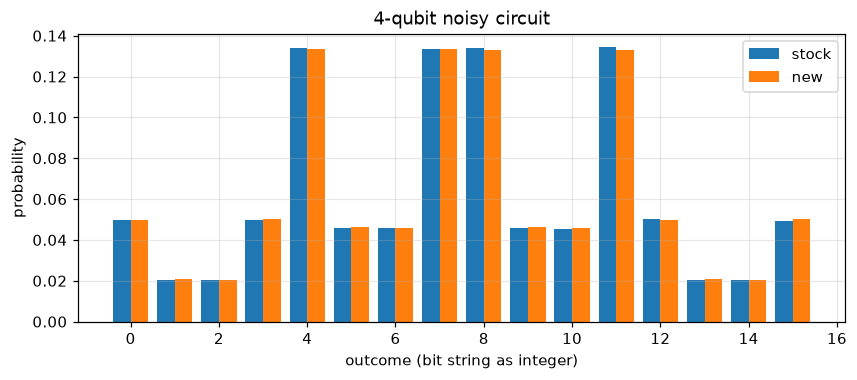

In [5]:
qc4 = noisy_random_circuit(4, 24, 0.05, seed=3)
SH = 400_000
pv_stock = Tableau(4, 2).to_probvector_noisy_pf(qc4, SH, seed=4)
out4 = NoisyCircuitSampler(qc4).sample(SH, seed=5)
pv_new = np.bincount(out4 @ (2 ** np.arange(3, -1, -1)), minlength=16) / SH

fig, ax = plt.subplots(figsize=(9, 3.4))
idx = np.arange(16)
ax.bar(idx - 0.2, pv_stock, 0.4, label="stock")
ax.bar(idx + 0.2, pv_new, 0.4, label="new")
ax.set(xlabel="outcome (bit string as integer)", ylabel="probability", title="4-qubit noisy circuit")
ax.legend()
plt.show()
print("max |difference| of the 16 probabilities:", np.abs(pv_stock - pv_new).max().round(5),
      " (shot noise is about", round(float(np.sqrt(0.25 / SH)), 5), ")")

## 3. Speed

### Time against the number of shots

The new sampler pays a small compile cost once; after that each shot costs a lookup.

   shots  stock [s]   new [s]  speed-up
   1,000      0.025     0.006      3.9x
   5,000      0.047     0.032      1.5x
  20,000      0.173     0.122      1.4x
  50,000      0.580     0.386      1.5x
 100,000      1.415     0.763      1.9x
 200,000      3.535     1.705      2.1x


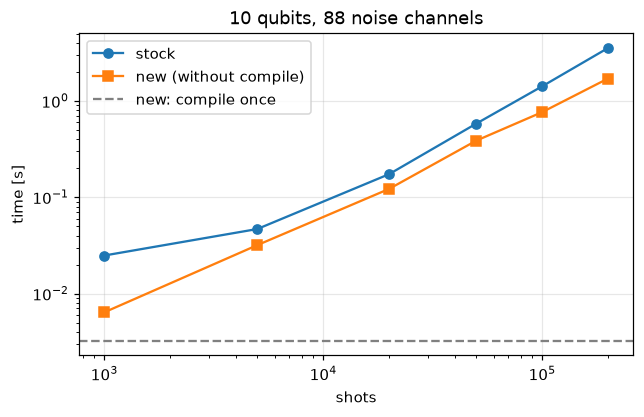

In [6]:
shot_list = [1_000, 5_000, 20_000, 50_000, 100_000, 200_000]
rows = []
for s in shot_list:
    _, ts = timed(lambda: Tableau(n, 2).sample_measurements_noisy_pf(qc, s, seed=1))
    _, tn = timed(lambda: sampler.sample(s, seed=2))
    rows.append((s, ts, tn))
rows = np.array(rows)

print(f"{'shots':>8} {'stock [s]':>10} {'new [s]':>9} {'speed-up':>9}")
for s, ts, tn in rows:
    print(f"{int(s):>8,} {ts:>10.3f} {tn:>9.3f} {ts / tn:>8.1f}x")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog(rows[:, 0], rows[:, 1], "o-", label="stock")
ax.loglog(rows[:, 0], rows[:, 2], "s-", label="new (without compile)")
ax.axhline(t_compile, color="gray", ls="--", label="new: compile once")
ax.set(xlabel="shots", ylabel="time [s]", title=f"{n} qubits, {sampler.n_locations} noise channels")
ax.legend()
plt.show()

### Time against circuit size

Circuit work scales with the number of gates for the stock sampler (every shot crosses every gate) and with noise locations times qubits for the lookup.

qubits  gates  channels  stock [s]  compile [s]  sample [s]  speed-up
     6     48        70       0.15         0.00        0.09      1.6x
    12     96       140       0.37         0.00        0.19      2.0x
    24    192       284       0.85         0.01        0.37      2.2x
    48    384       550       3.29         0.03        0.77      4.1x


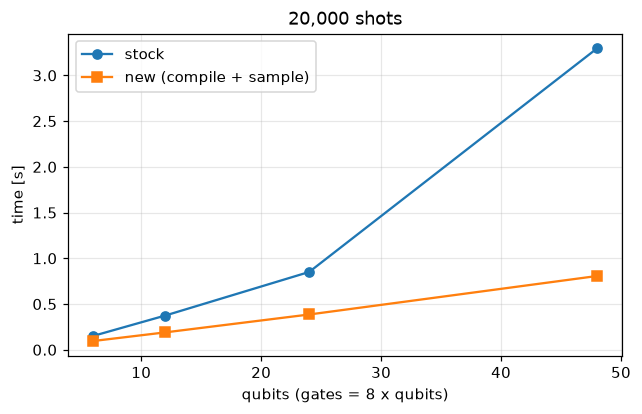

In [7]:
SH = 20_000
sizes = [(6, 48), (12, 96), (24, 192), (48, 384)]
print(f"{'qubits':>6} {'gates':>6} {'channels':>9} {'stock [s]':>10} {'compile [s]':>12} {'sample [s]':>11} {'speed-up':>9}")
res = []
for nq, sz in sizes:
    q = noisy_random_circuit(nq, sz, 0.01, seed=11)
    _, ts = timed(lambda: Tableau(nq, 2).sample_measurements_noisy_pf(q, SH, seed=1))
    smp, tc = timed(lambda: NoisyCircuitSampler(q))
    _, tn = timed(lambda: smp.sample(SH, seed=2))
    res.append((nq, ts, tc + tn))
    print(f"{nq:>6} {sz:>6} {smp.n_locations:>9} {ts:>10.2f} {tc:>12.2f} {tn:>11.2f} {ts / (tc + tn):>8.1f}x")

res = np.array(res)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(res[:, 0], res[:, 1], "o-", label="stock")
ax.plot(res[:, 0], res[:, 2], "s-", label="new (compile + sample)")
ax.set(xlabel="qubits (gates = 8 x qubits)", ylabel="time [s]", title=f"{SH:,} shots")
ax.legend()
plt.show()

### Rescanning the noise strength

The effect table depends on *where* the noise sits, not on how strong it is. Scanning nine noise strengths therefore recompiles nothing with the new sampler (`probs=`), while the stock sampler needs a circuit per strength.

9 noise strengths, 50,000 shots each: stock 12.79 s, new 5.41 s  ->  2.4x


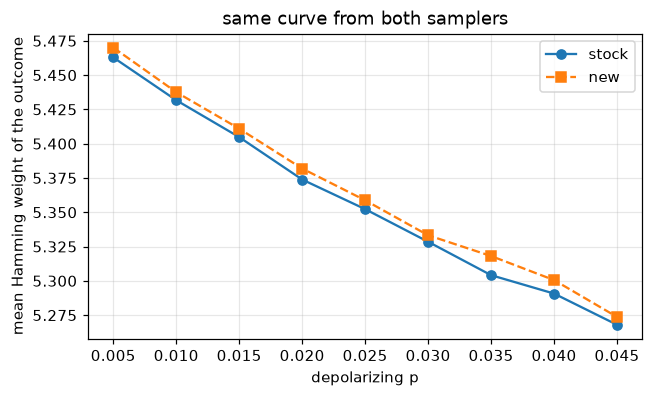

In [8]:
ps = np.linspace(0.005, 0.045, 9)
SH = 50_000


def stock_scan():
    return [Tableau(n, 2).sample_measurements_noisy_pf(noisy_random_circuit(n, SIZE, p, seed=7), SH, seed=1)
            for p in ps]


def new_scan():
    smp = NoisyCircuitSampler(qc)
    smp.precompute_noiseless_pool(SH, seed=3)          # clean tableau outcomes, drawn once
    return [smp.sample(SH, seed=2, probs=depolarizing(p).reshape(-1), use_pool=True) for p in ps]


res_stock, t_a = timed(stock_scan)
res_new, t_b = timed(new_scan)
print(f"9 noise strengths, {SH:,} shots each: stock {t_a:.2f} s, new {t_b:.2f} s  ->  {t_a / t_b:.1f}x")

w_stock = [r.sum(1).mean() for r in res_stock]
w_new = [r.sum(1).mean() for r in res_new]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ps, w_stock, "o-", label="stock")
ax.plot(ps, w_new, "s--", label="new")
ax.set(xlabel="depolarizing p", ylabel="mean Hamming weight of the outcome", title="same curve from both samplers")
ax.legend()
plt.show()

## Summary

* Same distribution: marginals, weight histograms and the full probability vector agree within shot noise.
* One compile per circuit; sampling then costs a table lookup per noise location, independent of the number of gates.
* Rescanning the noise strength reuses the table, and `precompute_noiseless_pool` additionally caches the noiseless tableau outcomes.

The speed-ups printed above are for this machine and this circuit family (random Clifford gates, a depolarizing channel after every gate): roughly 1.5-3x, growing with circuit size and with the number of shots. On surface-code encoders with noise only on the data qubits the gain is larger (about 4-5x for d = 3 ... 9), because the number of noise locations per gate is lower.